<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 28: Deep Boltzmann Machine / Convolutional Boltzmann Machine Simulation

**Category**: CO5 – Energy-Based and Generative Models  
**Objective**: Simulate bidirectional interlayer coupling and mean-field variational inference convergence in Deep Boltzmann Machines.


### Task 1: Mean-Field Inference Formulation in Deep Boltzmann Machines


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# A 2-Hidden-Layer DBM with bidirectional interactions:
# v <-> h_1 <-> h_2
# Mean-field updates:
# mu_1 = sigmoid(W1 * v + W2 * mu_2 + b1)
# mu_2 = sigmoid(W2^T * mu_1 + b2)

np.random.seed(42)
D_v, D_h1, D_h2 = 10, 8, 4

W1 = np.random.randn(D_v, D_h1) * 0.2
W2 = np.random.randn(D_h1, D_h2) * 0.2
b1 = np.zeros(D_h1)
b2 = np.zeros(D_h2)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -15, 15)))

# Simulate Mean-Field Iterative Convergence for a test pattern v
v_test = np.random.choice([0.0, 1.0], size=D_v)

mu1 = np.full(D_h1, 0.5)
mu2 = np.full(D_h2, 0.5)

convergence_history = []
for it in range(25):
    # Update mu_1 with influences from both v and mu_2
    mu1 = sigmoid(np.dot(v_test, W1) + np.dot(mu2, W2.T) + b1)
    # Update mu_2 with influence from mu_1
    mu2 = sigmoid(np.dot(mu1, W2) + b2)
    convergence_history.append((mu1.copy(), mu2.copy()))

print("Mean-Field Fixed-Point Iteration Converged across 25 Steps.")


Mean-Field Fixed-Point Iteration Converged across 25 Steps.


### Task 2: Mean-Field Variational State Convergence Trajectory


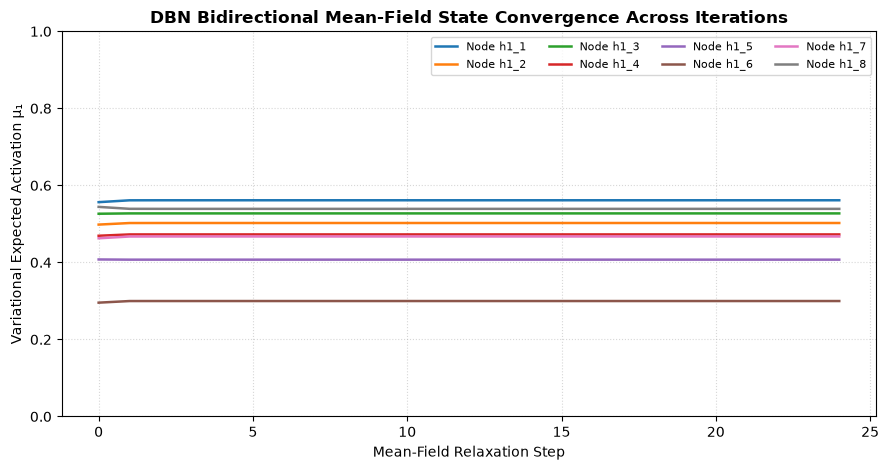

In [2]:
mu1_traj = np.array([pt[0] for pt in convergence_history])

plt.figure(figsize=(9, 4.8))
for i in range(D_h1):
    plt.plot(mu1_traj[:, i], lw=1.8, label=f'Node h1_{i+1}')

plt.title("DBN Bidirectional Mean-Field State Convergence Across Iterations", fontweight='bold')
plt.xlabel("Mean-Field Relaxation Step")
plt.ylabel("Variational Expected Activation μ₁")
plt.ylim(0, 1)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(ncol=4, loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()
